In [1]:
import seaborn as sns; df = sns.load_dataset("penguins")

In [2]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [4]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [5]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [6]:
df_cleaned = df.dropna()
len(df_cleaned)

333

In [7]:
len(df)

344

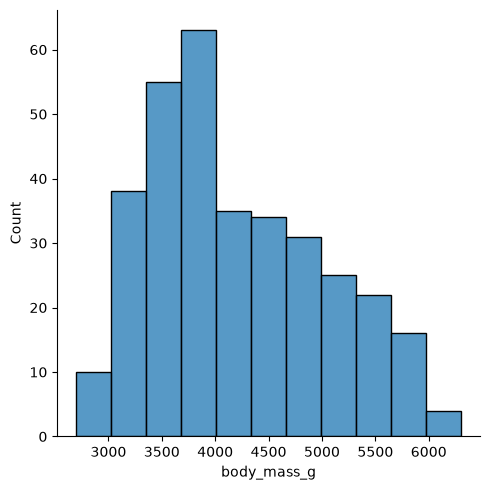

In [8]:
sns.displot(df_cleaned, x="body_mass_g")

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

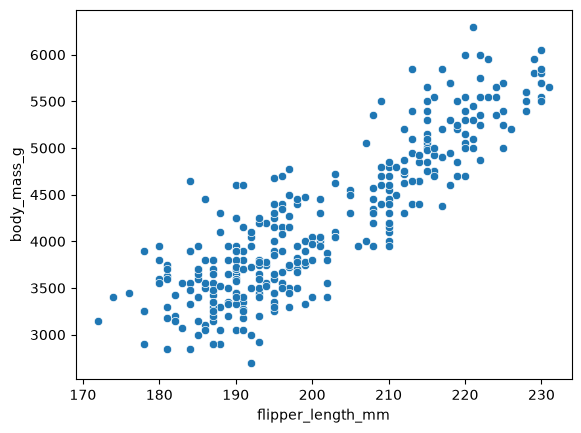

In [9]:
sns.scatterplot(df_cleaned, x="flipper_length_mm", y="body_mass_g")

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

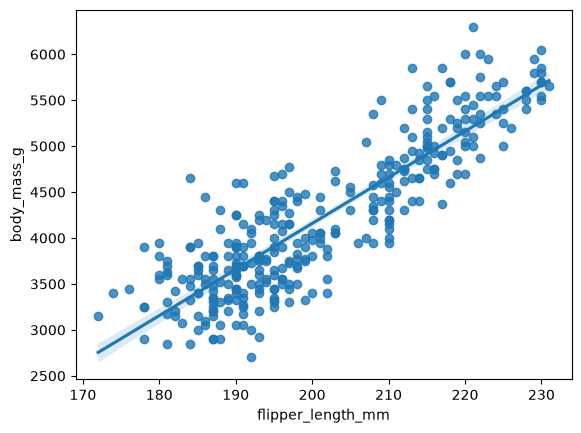

In [10]:
sns.regplot(df_cleaned, x="flipper_length_mm", y="body_mass_g")

<Axes: xlabel='species', ylabel='body_mass_g'>

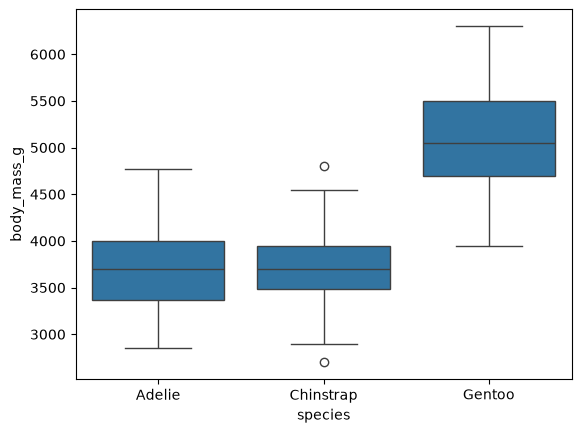

In [11]:
sns.boxplot(df_cleaned, x="species", y="body_mass_g")

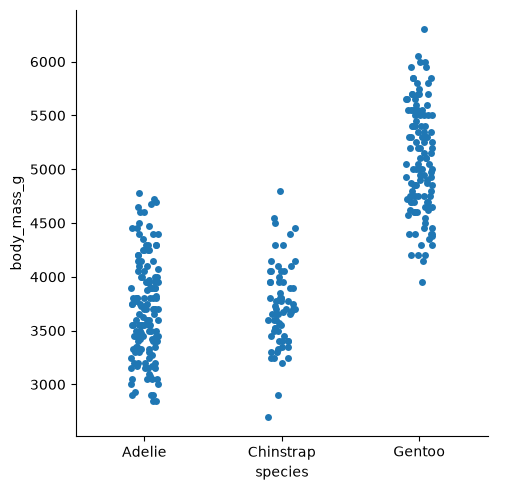

In [12]:
sns.catplot(df_cleaned, x="species", y="body_mass_g")

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [15]:
X = df_cleaned[["flipper_length_mm"]]
y = df_cleaned["body_mass_g"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 5)

In [17]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[50.17]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['flipper_length_mm']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5874
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [18]:
y_pred = model.predict(X_test)

In [19]:
r2 = r2_score(y_test, y_pred)
print(f"R-Squared: {r2: .4f}")

R-Squared:  0.7566


In [20]:
model.score(X_test, y_test)

0.7566245549354528

## Conclusions
1. I dropped the 11 penguins (about 3%) with any missing value, so every plot and the model use the same 333 complete rows, and scikit-learn can't fit on missing values anyway.
2. Body mass ranges from roughly 2,700 to 6,300 g, with one main hump around 3,500–4,000 g and a long tail toward the heavy end.
3. Gentoo penguins are clearly heavier than Adélie and Chinstrap, which are similar to each other; because there are fewer Gentoo than the other two combined, they form that right tail rather than a second hump.
4. Flipper length has a strong positive association with body mass: each extra millimeter of flipper goes with about 50 g more body mass, though this shows association, not causation, and species likely drives both.
5. On a held-out test set, the model's R² is 0.76, meaning flipper length removes about three-quarters of the error you'd get from always guessing the average weight; the rest comes from things the model doesn't see, like species and sex.